# Dataset donwload and description



In [2]:
import polars as pl
import numpy as np
import torch
import scipy.sparse as sp

import matplotlib.pyplot as plt

RANDOM_SEED = 42

We use [Amazon Review Data](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/), Video Games category. We download 5-core data (each item that have 5+ rates) and metadata.

In [3]:
dataset = pl.read_ndjson(r'data\Video_Games_5.json')
print(f'Num of reviews: {len(dataset)}')
print(dataset.columns)
dataset.sample(5)

Num of reviews: 497577
['overall', 'vote', 'verified', 'reviewTime', 'reviewerID', 'asin', 'reviewerName', 'reviewText', 'summary', 'unixReviewTime', 'style']


overall,vote,verified,reviewTime,reviewerID,asin,reviewerName,reviewText,summary,unixReviewTime,style
f64,str,bool,str,str,str,str,str,str,i64,struct[1]
5.0,"""2""",true,"""09 21, 2009""","""A1LA7YG1Y1FRZ3""","""B0016C3260""","""Jeffrey D. Corry""","""I had read a bit before I purc…","""Hidden Treasure""",1253491200,{null}
5.0,null,true,"""04 21, 2016""","""A3SQ2CVTYDC1I4""","""B00ZE3616K""","""kyle""","""So far so good""","""Could have worked as a ghost r…",1461196800,null
4.0,null,true,"""04 24, 2015""","""A2YS78CWZRFYPV""","""B00NLZAB6E""","""Eric""","""Launched really broken and is …","""Pretty Good""",1429833600,"{"" Video Game""}"
3.0,null,false,"""10 17, 2002""","""ARXU3FESTWMJJ""","""B00005O1GO""","""Mary Jo Sminkey""","""I am a HUGE fan of Roller Coas…","""Great for you animal lovers, b…",1034812800,{null}
5.0,"""6""",false,"""06 5, 2002""","""A10X0JN8KTK89H""","""B00002SUOV""","""ninjasuperstar""","""I've grown tired of first-pers…","""Cure for the common FPS""",1023235200,"{"" Video Game""}"


We have 497577 reviews in our dataset.

Description of dataset columns:

- **reviewerID** - ID of the reviewer, e.g. A2SUAM1J3GNN3B
- **asin** - ID of the product, e.g. 0000013714
- **reviewerName** - name of the reviewer
- **vote** - helpful votes of the review
- **style** - a disctionary of the product metadata, e.g., "Format" is "Video Game"
- **reviewText** - text of the review
- **summary** - summary of the review
- **unixReviewTime** - time of the review (unix time)
- **reviewTime** - time of the review (raw)
- **verified** - review left after a verified purchase
- **overall** - rating of the product (target)


We assume that product is relative if **overall**$\geq 4.0$. Recommendation is good if true overall at least 4.0

In [4]:
metadata = pl.read_ndjson(r'data\meta_Video_Games.json')
print(metadata.columns)
metadata.sample()

['category', 'tech1', 'description', 'fit', 'title', 'also_buy', 'tech2', 'brand', 'feature', 'rank', 'also_view', 'main_cat', 'similar_item', 'date', 'price', 'asin', 'imageURL', 'imageURLHighRes']


category,tech1,description,fit,title,also_buy,tech2,brand,feature,rank,also_view,main_cat,similar_item,date,price,asin,imageURL,imageURLHighRes
list[str],str,list[str],str,str,list[str],str,str,list[str],str,list[str],str,str,str,str,str,list[str],list[str]
"[""Video Games"", ""PlayStation 3"", … ""</span></span></span>""]","""""","[""The survival of humanity rests in the hands of those chosen by fate. You are a Grey Warden, one of the last of an ancient order of guardians who have defended the lands throughout the centuries. Betrayed by a trusted general in a critical battle, you must hunt down the traitor and bring him to justice. As you fight your way towards the final confrontation with an evil nemesis, you will face monstrous foes and engage in epic quests to unite the disparate peoples of a world at war. A romance with a seductive shapeshifter may hold the key to victory, or she may be a dangerous diversion from the heart of your mission. To be a leader, you must make ruthless decisions and be willing to sacrifice your friends and loved ones for the greater good of mankind."", """", … """"]","""""","""Dragon Age: Origins - Playstat…","[""B0047TLIBU"", ""B00JUFT1CE"", … ""B003A6X0H6""]","""""","""by Electronic Arts""","[""Scalable combat options that let you decide the level of control you have over your party, including NPCs. Issue orders, set your own tactical AI, or take control of any party member to lead the charge."", ""6 possible playable preludes known as Origin Stories which along with your play, define how your hero character will see the world, how it sees you and sets the tone for the entire story."", … ""At the heart of the storm sweeping across Ferelden. Decide the fate of nations, people and, ultimately, yourself. Just remember: for every choice, there is a consequence.""]","""["">#17,664 in Video Games (See…","[""B0045ZIEPY"", ""B0047TLIBU"", … ""B07JDV9ZD3""]","""Video Games""","""""","""""",""" <span class=""vert…","""B001IK5TJI""","[""https://images-na.ssl-images-amazon.com/images/I/51ygbr2aw6L._AC_SX150_SY75_CR,0,0,150,75_.jpg"", ""https://images-na.ssl-images-amazon.com/images/I/41oSsaUXw0L._AC_SX150_SY75_CR,0,0,150,75_.jpg"", … ""https://images-na.ssl-images-amazon.com/images/I/51yD2uwy21L._AC_SX150_SY75_CR,0,0,150,75_.jpg""]","[""https://images-na.ssl-images-amazon.com/images/I/51ygbr2aw6L.jpg"", ""https://images-na.ssl-images-amazon.com/images/I/41oSsaUXw0L.jpg"", … ""https://images-na.ssl-images-amazon.com/images/I/51yD2uwy21L.jpg""]"


Description of metadata columns:

- **asin** - ID of the product, e.g. 0000031852
- **title** - name of the product
- **feature** - bullet-point format features of the product
- **description** - description of the product
- **price** - price in US dollars (at time of crawl)
- **imageURL** - url of the product image
- **imageURLHighRes** - url of the high resolution product image
- **also buy**, **also view**, **similar_item** - related products
- **rank** - sales rank information
- **brand** - brand name
- **category** - list of categories the product belongs to
- **main_cat** - main category of the product
- **date** - date when product was published
- **fit**, **tech1**, **tech2** - unrelated to Video Games category

Now we count num of users and items, we need at least 1000 of both

In [5]:
print(f'Num of users: {dataset['reviewerID'].n_unique()}')
print(f'Num of items: {dataset['asin'].n_unique()}')
assert dataset['reviewerID'].n_unique() >= 10000
assert dataset['asin'].n_unique() >= 10000

Num of users: 55223
Num of items: 17408


# EDA and preparations

First we going to delete some columns because we don't know how to work with them for now (all comment-type data). This includes: reviewText and summary in dataset; feature and description in metadata.

Also we going to delete: reviewerName (same to reviewerID), reviewTime (same to unixReviewTime) in dataset; title (same to asin), imageURL and imageURLHighRes (we not going to work with images), fit, tech1, tech2 (mentioned earlier) in metadata

In [6]:
dataset_drop = ['reviewText', 'summary', 'reviewerName', 'reviewTime']
metadata_drop = ['feature', 'description', 'title', 'imageURL', 'imageURLHighRes', 'fit', 'tech1', 'tech2']
dataset = dataset.drop(dataset_drop, strict=False)
metadata = metadata.drop(metadata_drop, strict=False)
print(dataset.columns)
print(metadata.columns)

['overall', 'vote', 'verified', 'reviewerID', 'asin', 'unixReviewTime', 'style']
['category', 'also_buy', 'brand', 'rank', 'also_view', 'main_cat', 'similar_item', 'date', 'price', 'asin']


Now we check for null entries

In [7]:
dataset.describe()

statistic,overall,vote,verified,reviewerID,asin,unixReviewTime,style
str,f64,str,f64,str,str,f64,f64
"""count""",497577.0,"""107793""",497577.0,"""497577""","""497577""",497577.0,289237.0
"""null_count""",0.0,"""389784""",0.0,"""0""","""0""",0.0,208340.0
"""mean""",4.220456,null,0.66853,null,null,1.3678e9,null
"""std""",1.185424,null,null,null,null,1.2241e8,null
"""min""",1.0,"""1,000""",0.0,"""A0059486XI1Z0P98KP35""","""0700026398""",9.398592e8,null
"""25%""",4.0,null,null,null,null,1.3166e9,null
"""50%""",5.0,null,null,null,null,1.4102e9,null
"""75%""",5.0,null,null,null,null,1.4524e9,null
"""max""",5.0,"""99""",1.0,"""AZZTOUKVTUMVM""","""B01HIZGKOE""",1.5384e9,null


Vote is str type but values are integers. Let change null with 0 and change type to f64.

In [8]:
dataset = dataset.with_columns(
  pl.col('vote')
  .fill_null("0")
  .str.replace_all(",", "")
  .cast(pl.Float64, strict=False)
  .fill_null(0)
)

Also we going to find duplicates (same user-item pair) and delete them if they exist.

In [9]:
n_before = dataset.height
n_unique_pairs = dataset.select(["reviewerID", "asin"]).n_unique()
print("Unique pairs (reviewerID, asin):", n_unique_pairs)
print("Duplicates:", n_before - n_unique_pairs)

dups = dataset.filter(pl.struct("reviewerID", "asin").is_duplicated())
dups.sort(["reviewerID", "asin", "unixReviewTime"]).head(10)

Unique pairs (reviewerID, asin): 473427
Duplicates: 24150


overall,vote,verified,reviewerID,asin,unixReviewTime,style
f64,f64,bool,str,str,i64,struct[1]
5.0,0.0,true,"""A0059486XI1Z0P98KP35""","""B000WE8JES""",1402099200,null
5.0,0.0,true,"""A0059486XI1Z0P98KP35""","""B000WE8JES""",1402099200,null
5.0,0.0,true,"""A0220159ZRNBTRKLG08H""","""B000X37732""",1428710400,null
5.0,0.0,true,"""A0220159ZRNBTRKLG08H""","""B000X37732""",1428710400,null
3.0,0.0,true,"""A0685888WB02Q69S553P""","""B0017XFP8G""",1416268800,{null}
3.0,0.0,true,"""A0685888WB02Q69S553P""","""B0017XFP8G""",1416268800,{null}
5.0,0.0,true,"""A0695568PX4DBZOQDN8""","""B0016B28WU""",1361318400,"{"" Video Game""}"
5.0,0.0,true,"""A0695568PX4DBZOQDN8""","""B0016B28WU""",1361318400,"{"" Video Game""}"
5.0,0.0,true,"""A0815906MFVDTIFHGRQR""","""B0017KIBAI""",1384819200,null


If there reviews with different review time then we want to keep a last review as "final opinion"

In [10]:
dataset = (
    dataset
    .sort("unixReviewTime")
    .unique(subset=["reviewerID", "asin"], keep="last", maintain_order=True)
)

print("After clearing:", dataset.height)
print("Duplicates:", dataset.select(["reviewerID", "asin"]).is_duplicated().any())

After clearing: 473427
Duplicates: False


We want to restore 5-core strcture - that means we need an additional clear

In [11]:
while True:
    n_before = dataset.height
    dataset = (
        dataset
        .filter(pl.len().over("reviewerID") >= 5)
        .filter(pl.len().over("asin") >= 5)
    )
    if dataset.height == n_before:
        break

We want to look at **overall** distribution first

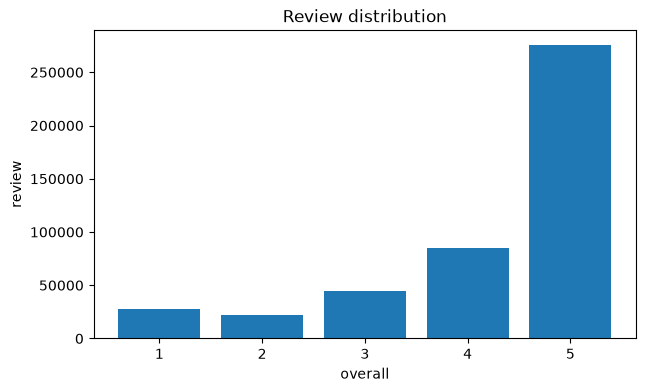

In [12]:
vc = dataset["overall"].value_counts().sort("overall")
labels = [str(int(v)) for v in vc["overall"].to_list()]
counts = vc["count"].to_list()

plt.figure(figsize=(7, 4))
plt.bar(labels, counts)
plt.xlabel("overall")
plt.ylabel("review")
plt.title("Review distribution")
plt.show()

Now we look at **vote** and **verified** distribution

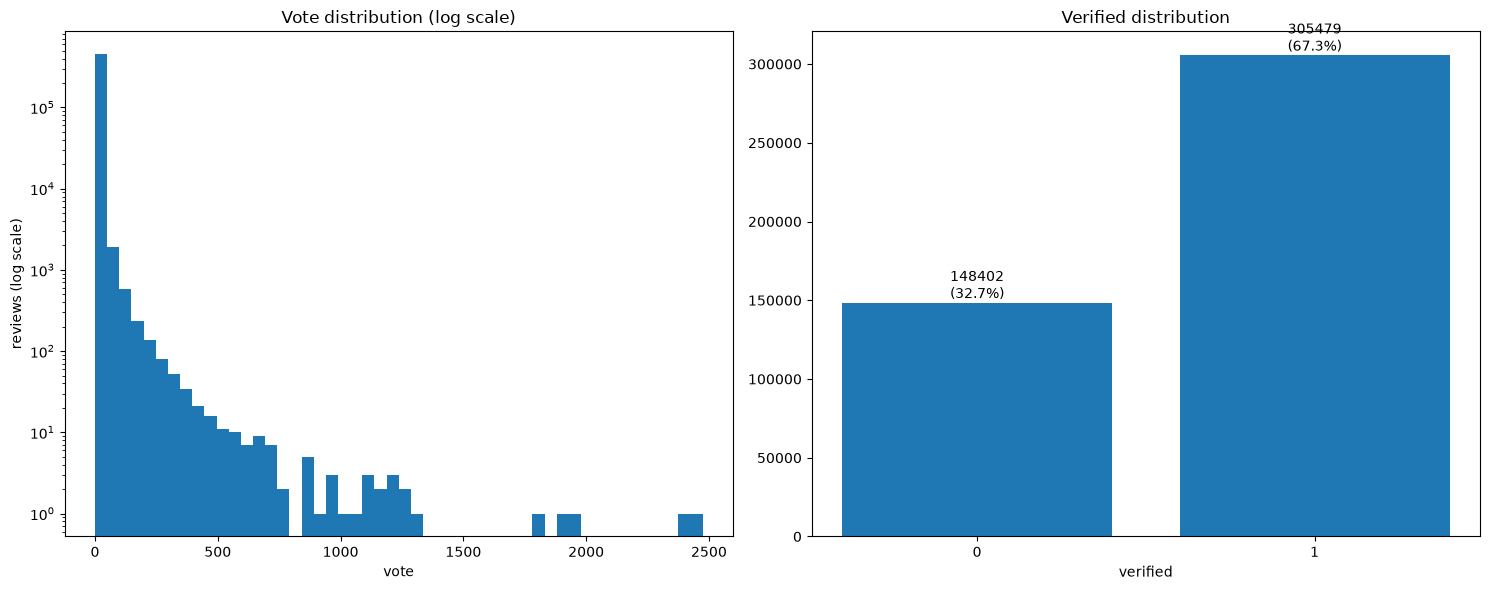

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].hist(dataset["vote"], bins=50)
axes[0].set_yscale("log")
axes[0].set_xlabel("vote")
axes[0].set_ylabel("reviews (log scale)")
axes[0].set_title("Vote distribution (log scale)")

vc = dataset["verified"].value_counts().sort("verified")
labels = [str(int(v)) if v is not None else "null" for v in vc["verified"].to_list()]
counts = vc["count"].to_list()

axes[1].bar(labels, counts)
axes[1].set_xlabel("verified")
axes[1].set_title("Verified distribution")
for i, c in enumerate(counts):
    axes[1].text(i, c, f"{c}\n({100 * c / dataset.height:.1f}%)", ha="center", va="bottom")

plt.tight_layout()
plt.show()

Next we look at users activity and items popularity

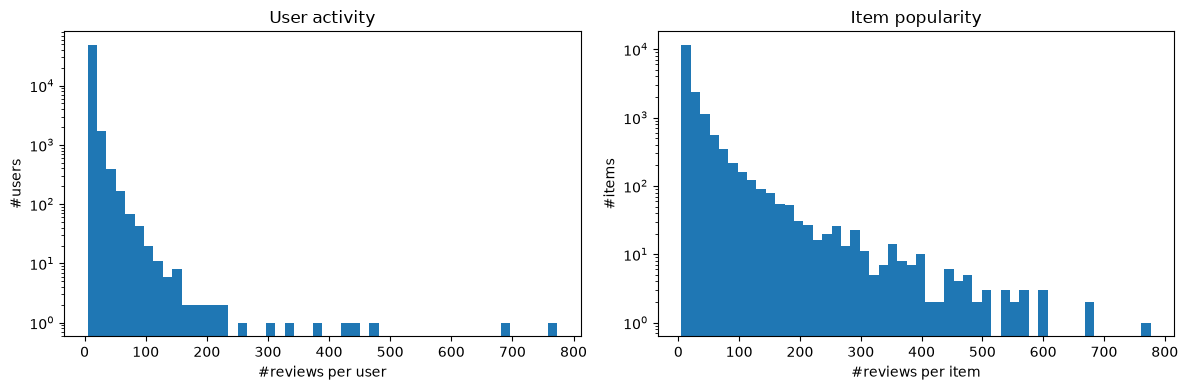

In [14]:
user_activity = dataset.group_by("reviewerID").len().rename({"len": "reviews"})
item_popularity = dataset.group_by("asin").len().rename({"len": "reviews"})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(user_activity["reviews"], bins=50)
axes[0].set_yscale("log")
axes[0].set_xlabel("#reviews per user")
axes[0].set_ylabel("#users")
axes[0].set_title("User activity")

axes[1].hist(item_popularity["reviews"], bins=50)
axes[1].set_yscale("log")
axes[1].set_xlabel("#reviews per item")
axes[1].set_ylabel("#items")
axes[1].set_title("Item popularity")

plt.tight_layout()
plt.show()

Now we want to look at sparsity of out User-Item matrix

In [15]:
num_user = dataset['reviewerID'].n_unique()
num_item = dataset['asin'].n_unique()
num_filled = len(dataset)
matrix_size = num_user * num_item
sparsity = num_filled / matrix_size * 100
print(f'User-Item matrix sparsity: {sparsity:.4f} %')

User-Item matrix sparsity: 0.0531 %


We also have metadata DataFrame but it describes each item, not interaction. Values here unique to each entry - we can't look for any distributions

# Rating protocol

First, we need to determine train/val/test partition. We going to use cronological order through each user. That means for each user we sort his reviews by unixReviewerTime and send first 80% reviews to train, next 10% to val and last 10% to test. unixReviewTime known to the day - that means we might have reviews with same user and timestamp. In this case we sort by item (asin) just for determined behaviour

In [16]:
dataset = (
    dataset
    .sort(["reviewerID", "unixReviewTime", "asin"])
    .with_columns(
        pl.int_range(pl.len()).over("reviewerID").alias("pos"),
        pl.len().over("reviewerID").alias("n"),
    )
    .with_columns(
        (pl.col("n") * 0.1).floor().clip(lower_bound=1).cast(pl.Int64).alias("hold")
    )
)

train = dataset.filter(pl.col("pos") < pl.col("n") - 2 * pl.col("hold"))
val   = dataset.filter(
    (pl.col("pos") >= pl.col("n") - 2 * pl.col("hold")) &
    (pl.col("pos") <  pl.col("n") - pl.col("hold"))
)
test  = dataset.filter(pl.col("pos") >= pl.col("n") - pl.col("hold"))

Next step - we want to handle new users and items. We have 5-core which means that we have same set of users in train/val/test (at least 3/1/1). Some models (e.g. U2U kNN) can't handle new items. It would be fair if we just delete those for every model. In total - we deleting items in val/test which wasn't in train. Also we want to check how many objects was deleted

In [17]:
train_items = train.select("asin").unique()

val_n, test_n = val.height, test.height

val  = val.join(train_items, on="asin", how="semi")
test = test.join(train_items, on="asin", how="semi")

print(f"val:  Deleted {val_n - val.height} out of {val_n} ({100 * (val_n - val.height) / val_n:.2f}%)")
print(f"test: Deleted {test_n - test.height} out of {test_n} ({100 * (test_n - test.height) / test_n:.2f}%)")

val:  Deleted 102 out of 56560 (0.18%)
test: Deleted 335 out of 56560 (0.59%)


# Models training

As main metric we choose NDCG@10. We choose it because it give more weight to items on the top of list which good for recommendations

In [19]:
def ndcg_at_k(model, R, rel, k=10):
  scores = []

  for u in range(R.shape[0]):
    relevant = set(rel[u].indices)
    if len(relevant) == 0:
      continue

    pred = model.predict([u])[0]
    pred[R[u].indices] = -np.inf
    top = np.argsort(-pred)[:k]

    dcg = 0
    for pos, item in enumerate(top):
      if item in relevant:
        dcg += 1 / np.log2(pos + 2)

    idcg = 0
    for pos in range(min(len(relevant), k)):
      idcg += 1 / np.log2(pos + 2)

    scores.append(dcg / idcg)

  return np.mean(scores)

We make sparse matrixes to work with them later

In [20]:
users = train.select("reviewerID").unique().sort("reviewerID").with_row_index("uidx")
items = train.select("asin").unique().sort("asin").with_row_index("iidx")
n_users, n_items = users.height, items.height

tr = (
    train
    .join(users, on="reviewerID")
    .join(items, on="asin")
    .select("uidx", "iidx", "overall")
)
R = sp.csr_matrix(
    (
        tr["overall"].to_numpy().astype(np.float32),
        (tr["uidx"].to_numpy(), tr["iidx"].to_numpy()),
    ),
    shape=(n_users, n_items),
)

And also we add popularity-baseline

In [39]:
v = val.join(users, on="reviewerID").join(items, on="asin").filter(pl.col("overall") >= 4)

rel = sp.csr_matrix(
  (np.ones(v.height, dtype=np.float32), (v["uidx"].to_numpy(), v["iidx"].to_numpy())),
  shape=R.shape,
)

In [40]:
t = test.join(users, on="reviewerID").join(items, on="asin").filter(pl.col("overall") >= 4)

t_rel = sp.csr_matrix(
  (np.ones(t.height, dtype=np.float32), (t["uidx"].to_numpy(), t["iidx"].to_numpy())),
  shape=R.shape,
)

In [41]:
class Popularity():
  def __init__(self, R):
    self.pop = R.getnnz(axis=0).astype(float)

  def predict(self, users):
    return np.tile(self.pop, (len(users), 1))

print(ndcg_at_k(Popularity(R), R, rel, k=10))
print(ndcg_at_k(Popularity(R), R, t_rel, k=10))

0.00546591780197456
0.004785372735121599


## Collaborative filtration

I use U2U method (we have ~34 review per user). Also U2U matrix is 10k x 10k which much easier to compute than I2I matrix that have 50k x 50k size

Similarity calculated as: $s(u,v) = \frac{\sum_{i \in I_u \cap I_v} (r_{ui} − \overline{r}_u)(r_{vi} − \overline{r}_v)}{ \sqrt{\sum_{i \in I_u} (r_{ui} − \overline{r}_u)^2} · \sqrt{\sum_{i \in I_v} (r_{vi} − \overline{r}_v)^2 }}$

We going to predict **overall** so we can use: $\hat{r}_{ui} = \overline{r}_u + \frac{\sum_{v \in N_k(u)} s(u,v)(r_{vi} − \overline{r}_v)}{\sum_{v \in N_k(u)} |s(u,v)|}$

In [23]:
from models.collaborative_filtration import CollabFiltration

ks = [3, 5, 7, 10, 50, 100, 200]
for k in ks:
  cf = CollabFiltration(R).fit(k=k)
  print(f"Collaborative Filtration with k={k} - NDCG@10 (val): {ndcg_at_k(cf, R, rel, k=10):.4f}")

Collaborative Filtration with k=3 - NDCG@10 (val): 0.0056
Collaborative Filtration with k=5 - NDCG@10 (val): 0.0063
Collaborative Filtration with k=7 - NDCG@10 (val): 0.0059
Collaborative Filtration with k=10 - NDCG@10 (val): 0.0057
Collaborative Filtration with k=50 - NDCG@10 (val): 0.0032
Collaborative Filtration with k=100 - NDCG@10 (val): 0.0022
Collaborative Filtration with k=200 - NDCG@10 (val): 0.0016


We can see the best score on k=5 (NDCG@10 = 0.0063)
We launch this version of model on test

In [ ]:
cf = CollabFiltration(R).fit(k=5)
print(f"Collaborative Filtration - NDCG@10 (test): {ndcg_at_k(cf, R, t_rel, k=10):.4f}")

Collaborative Filtration - NDCG@10 (test): 0.0046


## ALS

We use ALS with explicit feedback (**overall**). We use model with assumption that $\hat{r}_{ui} = \mu + p_u^Tq_i$

First we look for the best n_factors and reg. Then we take the best pair and found best n_iters

In [35]:
from models.als import ALS

np.random.seed(RANDOM_SEED)
results = []

for n_factors in [16, 32, 64]:
  for reg in [0.01, 0.05, 0.1, 0.5, 1.0]:
    np.random.seed(42)
    als = ALS(n_factors=n_factors, reg=reg, n_iters=10).fit(R)
    score = ndcg_at_k(als, R, rel, k=10)
    results.append((n_factors, reg, score))
    print(f'n_factors={n_factors}, reg={reg}, NDCG@10 = {round(score, 5)}')

res = pl.DataFrame(results, schema=["n_factors", "reg", "ndcg"], orient="row")
res.sort("ndcg", descending=True).head(10)

n_factors=16, reg=0.01, NDCG@10 = 0.0002
n_factors=16, reg=0.05, NDCG@10 = 0.00029
n_factors=16, reg=0.1, NDCG@10 = 0.00022
n_factors=16, reg=0.5, NDCG@10 = 0.0003
n_factors=16, reg=1.0, NDCG@10 = 0.00054
n_factors=32, reg=0.01, NDCG@10 = 0.0005
n_factors=32, reg=0.05, NDCG@10 = 0.00142
n_factors=32, reg=0.1, NDCG@10 = 0.00135
n_factors=32, reg=0.5, NDCG@10 = 0.00088
n_factors=32, reg=1.0, NDCG@10 = 0.00061
n_factors=64, reg=0.01, NDCG@10 = 0.00348
n_factors=64, reg=0.05, NDCG@10 = 0.00433
n_factors=64, reg=0.1, NDCG@10 = 0.00367
n_factors=64, reg=0.5, NDCG@10 = 0.0015
n_factors=64, reg=1.0, NDCG@10 = 0.00074


n_factors,reg,ndcg
i64,f64,f64
64,0.05,0.004334
64,0.1,0.003673
64,0.01,0.003481
64,0.5,0.001499
32,0.05,0.001424
32,0.1,0.001346
32,0.5,0.000879
64,1.0,0.000735
32,1.0,0.000613


Best result on val is n_factors=64 and reg=0.05. Now we searching optimal n_iters

In [36]:
for n_iters in [3, 5, 10, 20, 30]:
  als = ALS(n_factors=64, reg=0.05, n_iters=n_iters).fit(R)
  print(f'n_iters={n_iters}, NDCG@10={round(ndcg_at_k(als, R, rel, k=10), 5)}')

n_iters=3, NDCG@10=0.0023
n_iters=5, NDCG@10=0.00418
n_iters=10, NDCG@10=0.00462
n_iters=20, NDCG@10=0.00354
n_iters=30, NDCG@10=0.00378


Best result with n_iters=10. Let's check our model on test

In [38]:
als = ALS(n_factors=64, reg=0.05, n_iters=10).fit(R)
print(f'NDCG@10={round(ndcg_at_k(als, R, t_rel, k=10), 5)}')

NDCG@10=0.00236


## EASE

Next model is EASE.

In [46]:
from models.ease import EASE

for reg in [10, 50, 100, 300, 1000, 3000]:
  ease = EASE(reg=reg).fit(R)
  score = ndcg_at_k(ease, R, rel, k=10)
  print(f'reg={reg}, NDCG@10={round(score, 5)}')

reg=10, NDCG@10=0.0602
reg=50, NDCG@10=0.06388
reg=100, NDCG@10=0.06345
reg=300, NDCG@10=0.061
reg=1000, NDCG@10=0.05805
reg=3000, NDCG@10=0.05564


Best result with reg=50, we take it for a test

In [ ]:
ease = EASE(reg=50).fit(R)
score = ndcg_at_k(ease, R, t_rel, k=10)
print(f'NDCG@10={round(score, 5)}')